/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step


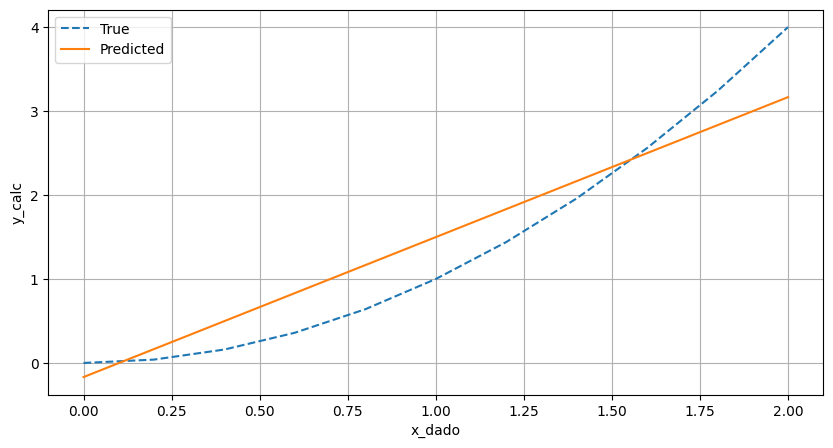

In [1]:
# TensorFlow 2.x version of the single-neuron model that tries to learn y = x²
# Comments are in English, as requested.

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Data
x_dado = np.linspace(0, 2, 11).astype(np.float32).reshape(-1, 1)  # shape (11, 1)
y_calc = (x_dado ** 2).astype(np.float32)                         # shape (11, 1)

# Single-neuron (linear) model: ŷ = w·x + b
model = tf.keras.Sequential([
    tf.keras.layers.Dense(1, input_shape=(1,), activation='linear')
])

# Optimizer and loss mimic the manual SGD loop
model.compile(optimizer=tf.keras.optimizers.SGD(learning_rate=5e-4),
              loss='mse')

# Train
history = model.fit(x_dado, y_calc,
                    epochs=1_000,
                    verbose=0
)

# Predictions
predicted = model.predict(x_dado)

# Plot: true vs. predicted
plt.figure(figsize=(10, 5))
plt.plot(x_dado, y_calc,  '--', label='True')
plt.plot(x_dado, predicted, '-', label='Predicted')
plt.xlabel('x_dado')
plt.ylabel('y_calc')
plt.legend()
plt.grid(True)
plt.show()
